# WR Doppelgänger

Scouts say things like "he moves like Cooper Kupp." This notebook checks that idea with tracking data.

We turn every wide receiver's routes into a **movement fingerprint**: how fast he gets off the line, how fast he runs,
how hard he brakes, how sharply he cuts, and how straight his paths are. Then we:

1. **Check the fingerprint is real.** Can a model tell which receiver ran a route, from movement alone?
2. **Find doppelgängers.** For each receiver, who on other teams moves most like him?
3. **Find budget doppelgängers.** Which cheap receivers move like expensive stars?

**Data:** NFL Big Data Bowl, 2021 season, weeks 1–8, passing plays only.

**To run:** put the raw data in `data/data/` (see `OUT_OF_REPO.md`), pick the `.venv` kernel, then *Restart & Run All*.
The whole notebook takes about 3 minutes.

In [1]:
import os
import sys
from pathlib import Path

# Work from the repo root so every path matches the scripts in src/.
ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import plotly.io as pio
from IPython.display import Image, display

import load_data, features, fingerprint, doppelganger, budget, visuals

pio.renderers.default = "plotly_mimetype+notebook_connected"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 2)
OUT = ROOT / "outputs"
print("Repo root:", ROOT)
print("Raw data found:", (ROOT / "data/data/tracking").is_dir())

Repo root: c:\hack_nfl\shadow
Raw data found: True


## Step 1. Load the routes

We keep only **wide receivers who ran a pass route**. For each route we cut the tracking data from the **snap** to the
**throw** (or sack). Tracking is recorded 10 times per second.

We also flip plays that go to the left, so every play runs left to right.

In [2]:
load_data.build_wr_routes()
routes = pd.read_parquet(OUT / "wr_routes.parquet")
routes.head()

  loaded 20/122 games


  loaded 40/122 games


  loaded 60/122 games


  loaded 80/122 games


  loaded 100/122 games


  loaded 120/122 games
  loaded 122/122 games



WR route rows in PFF:          23,033
Plays dropped (no snap/end):   24
Routes dropped (<15 frames):  66
Routes kept:                   22,900
WRs:                           210
Frame rows:                    724,272
Frames per route:
count    22900.0
mean        31.6
std         11.4
min         15.0
25%         24.0
50%         29.0
75%         36.0
max         99.0
Duplicate rows (full):         0


Duplicate rows (route+frame):  0
Saved -> outputs\wr_routes.parquet


,gameId,playId,nflId,frameId,team,playDirection,x,y,s,a,dis,o,dir,event,snapFrame,endFrame
0,2021090900,97,35634,6,TB,right,41.04,36.77,0.48,2.61,0.04,113.75,54.53,ball_snap,6,38
1,2021090900,97,35634,7,TB,right,41.10,36.82,0.92,3.92,0.08,111.77,52.35,NaN,6,38
2,2021090900,97,35634,8,TB,right,41.20,36.90,1.49,5.17,0.12,109.27,52.50,NaN,6,38
3,2021090900,97,35634,9,TB,right,41.36,37.02,2.15,5.11,0.20,108.27,51.18,NaN,6,38
4,2021090900,97,35634,10,TB,right,41.54,37.18,2.63,4.41,0.24,106.34,49.19,NaN,6,38


## Step 2. Describe each route with movement features

Each route becomes one row of numbers. These describe **how** the receiver moves, never **where** he lines up:

| Feature | In plain words |
|---|---|
| `release_speed`, `release_accel` | How explosive he is in the first second |
| `top_speed`, `avg_speed` | How fast he runs |
| `max_decel` | How hard he brakes |
| `cut_sharpness`, `speed_kept_in_cut` | How sharp his biggest cut is, and how much speed he keeps through it |
| `straightness` | Straight lines (1.0) or wavy paths |
| `route_time` | How long the route lasts before the throw |

We drop routes where the QB ran (not a real route) and routes where the receiver was already moving at the snap
(that fakes a fast release).

In [3]:
features.main()
feats = pd.read_parquet(OUT / "route_features.parquet")
feats[features.FEATURES].describe().T[["mean", "25%", "50%", "75%"]]

Dropped 1,235 routes on QB-run plays


Dropped 649 routes with pre-snap motion (> 2.0 yd/s at snap)


       release_speed  release_accel  top_speed  avg_speed  max_decel  cut_sharpness  speed_kept_in_cut   has_cut  straightness  route_time
count       21016.00       21016.00   21016.00   21016.00   21016.00       18177.00            5187.00  21016.00      21016.00    21016.00
mean            4.16           4.69       6.81       4.22      -2.20          38.96               0.69      0.25          0.95        3.09
std             0.95           1.06       1.35       1.10       2.58          34.37               0.41      0.43          0.09        1.09
min             0.00           0.00       0.42       0.25     -10.00           0.14               0.01      0.00          0.06        1.50
25%             3.60           4.01       5.96       3.43      -3.80          16.23               0.29      0.00          0.95        2.40
50%             4.29           4.74       6.98       4.27      -1.40          29.23               0.74      0.00          0.98        2.80
75%             4.83       

,mean,25%,50%,75%
release_speed,4.16,3.60,4.29,4.83
release_accel,4.69,4.01,4.74,5.36
top_speed,6.81,5.96,6.98,7.75
avg_speed,4.22,3.43,4.27,5.00
max_decel,-2.20,-3.80,-1.40,0.00
cut_sharpness,38.96,16.23,29.23,48.81
speed_kept_in_cut,0.69,0.29,0.74,1.08
has_cut,0.25,0.00,0.00,0.00
straightness,0.95,0.95,0.98,0.99
route_time,3.09,2.40,2.80,3.50


## Step 3. Build fingerprints and check they are real

A receiver's **fingerprint** is the average (and spread) of his route features. We use receivers with at least 80 routes.

To check the fingerprint is real, we ask: **can we tell who ran a route, on games the model never saw?**
Random guessing among 110 receivers is right about 1% of the time.

- **Season fingerprint:** build a fingerprint from half of a player's games, then find him among all 110 players using
  the other half.
- **Single route:** guess the player from one route only. This is much harder.
- **vs. teammates:** pick between teammates only. They share the same QB and play calls, so a win here shows personal
  style, not team scheme.

This step takes about a minute.

In [4]:
fingerprint.main()

WRs with >= 80 routes: 110   routes: 18,053

Split-half fingerprint test (20 random game halves)


  WRs with >= 20 routes in both halves: ~100

Who ran this route? (5 game splits)


  split 1: train 91 games, test 31 games / 4,631 routes


  split 2: train 91 games, test 31 games / 4,433 routes


  split 3: train 91 games, test 31 games / 4,754 routes


  split 4: train 91 games, test 31 games / 4,634 routes


  split 5: train 91 games, test 31 games / 4,739 routes

All tests on unseen games vs chance:
                                  test  accuracy    sd  chance  x_chance
         Split-half fingerprint, top-1     0.115 0.029   0.010    11.437
         Split-half fingerprint, top-5     0.327 0.046   0.050     6.522
Split-half fingerprint, teammates only     0.528 0.045   0.321     1.643
          Single route, all WRs, top-1     0.022 0.003   0.009     2.392
          Single route, all WRs, top-5     0.094 0.004   0.045     2.073
          Single route, teammates only     0.391 0.017   0.305     1.282

Signature Score = top-5 recall on unseen games, mean of 5 splits (chance 0.045).
Tiers are terciles. Order inside a tier is noise, so names are alphabetical.

DISTINCTIVE (37 WRs, 2.3x-5.1x chance), alphabetical:
  A.J. Brown (TEN), A.J. Green (ARI), Allen Robinson (CHI), Amon-Ra St. Brown (DET), Braxton Berrios (NYJ), Bryan Edwards (LV)
  Chester Rogers (TEN), Cole Beasley (BUF), Cooper Kup


Permutation importance (test log-loss increase when shuffled):
          feature  importance    std
    release_speed      0.1191 0.0047
    release_accel      0.0959 0.0018
        top_speed      0.0563 0.0067
        avg_speed      0.0266 0.0041
        max_decel      0.0214 0.0027
     straightness      0.0182 0.0020
       route_time      0.0169 0.0025
speed_kept_in_cut      0.0052 0.0017
    cut_sharpness      0.0001 0.0032
          has_cut      0.0000 0.0000

Fingerprint: 110 WRs x 28 standardized columns
Saved -> outputs/wr_fingerprints.csv, wr_fingerprints_raw.csv, signature_scores.csv, classifier_summary.csv, feature_importance.csv


In [5]:
clf = pd.read_csv(OUT / "classifier_summary.csv")
clf.assign(accuracy=clf["accuracy"].map("{:.1%}".format),
           chance=clf["chance"].map("{:.1%}".format),
           x_chance=clf["x_chance"].map("{:.1f}x".format))[["test", "accuracy", "chance", "x_chance"]]

,test,accuracy,chance,x_chance
0,"Split-half fingerprint, top-1",11.5%,1.0%,11.4x
1,"Split-half fingerprint, top-5",32.7%,5.0%,6.5x
2,"Split-half fingerprint, teammates only",52.8%,32.1%,1.6x
3,"Single route, all WRs, top-1",2.2%,0.9%,2.4x
4,"Single route, all WRs, top-5",9.4%,4.5%,2.1x
5,"Single route, teammates only",39.1%,30.5%,1.3x


**What this means:** from half a season of routes, we pick the right receiver out of 110 about **11 times** more often
than guessing. A single route is too short to tell much (about 2.8 seconds of tracking).

Which features matter most? Speed off the line and top speed carry most of the signal.

In [6]:
pd.read_csv(OUT / "feature_importance.csv")

,feature,importance,std
0,release_speed,1.19e-01,4.73e-03
1,release_accel,9.59e-02,1.84e-03
2,top_speed,5.63e-02,6.65e-03
3,avg_speed,2.66e-02,4.11e-03
4,max_decel,2.14e-02,2.66e-03
5,straightness,1.82e-02,2.01e-03
6,route_time,1.69e-02,2.51e-03
7,speed_kept_in_cut,5.19e-03,1.71e-03
8,cut_sharpness,1.29e-04,3.17e-03
9,has_cut,0.00e+00,0.00e+00


## Step 4. Find doppelgängers

Two receivers are doppelgängers when their fingerprints point the same way (cosine similarity, 1.0 = identical).
We skip teammates, because they share a scheme and a GM would be shopping on other teams anyway.

Two checks on each match:
- **Stable:** split each player's games into two random halves, 20 times. A pair is *stable* if they stay in each
  other's top 5 in both halves at least half the time.
- **Hub:** some players show up in many top-5 lists. Being "his doppelgänger" says little for them, so we flag them.

This step takes about a minute.

In [7]:
doppelganger.main()

STABILITY, teammates excluded (20 random game halves)
  top-5 overlap between halves: 10.9% (chance 5.2%, 2.1x)
  stable top-5 pairs (both halves in >= 50% of repeats): 10 of 550

HUBS = common profile (in >= 10 top-5 lists, or named):
  Cole Beasley (12), Emmanuel Sanders (14), Hunter Renfrow (11), Jalen Guyton (10), Keelan Cole (14), Keenan Allen (17), Marquise Brown (10), Mike Evans (12), Mike Williams (10), Robby Anderson (10), Stefon Diggs (11), Tyler Lockett (12), Tyreek Hill (10)

SANITY: average gap to top-5 matches vs to a random non-teammate
  feature              top-5 gap  random gap   ratio  unit
  top_speed_mean           0.176       0.321    0.55  yd/s
  release_speed_mean       0.175       0.312    0.56  yd/s
  release_accel_mean       0.211       0.296    0.71  yd/s^2
  cut_rate                 0.037       0.066    0.55  share
  weight                  16.073      16.445    0.98  lb (not in fingerprint)
  height_in                2.518       2.599    0.97  in (not in f

**Look up any receiver.** Change the name below to try another player.

In [8]:
pairs = pd.read_csv(OUT / "doppelgangers.csv")
doppelganger.find_doppelgangers("Cooper Kupp", pairs=pairs)

,match_displayName,match_team,similarity,rank,built_like,stable_rate,stable,match_is_hub
0,K.J. Osborn,MIN,0.82,1,True,0.50,True,False
1,Tyler Johnson,TB,0.81,2,True,0.05,False,False
2,Keenan Allen,LAC,0.74,3,True,0.15,False,True
3,Mike Williams,LAC,0.68,4,True,0.05,False,True
4,Tee Higgins,CIN,0.66,5,True,0.05,False,False


In [9]:
doppelganger.find_doppelgangers("Justin Jefferson", pairs=pairs)

,match_displayName,match_team,similarity,rank,built_like,stable_rate,stable,match_is_hub
0,Henry Ruggs,LV,0.81,1,False,0.60,True,False
1,Kalif Raymond,DET,0.66,2,False,0.25,False,False
2,Keelan Cole,NYJ,0.62,3,True,0.00,False,True
3,Tyler Lockett,SEA,0.60,4,False,0.00,False,True
4,Trinity Benson,DET,0.59,5,False,0.00,False,False


Only show matches who are also **built like** him (within 15 lb and 2 inches):

In [10]:
doppelganger.find_doppelgangers("Stefon Diggs", k=3, pairs=pairs, built_only=True)

,match_displayName,match_team,similarity,rank,built_like,stable_rate,stable,match_is_hub
0,Chester Rogers,TEN,0.79,1,True,0.0,False,False
1,Freddie Swain,SEA,0.71,6,True,0.0,False,False
2,James Proche,BAL,0.59,10,True,0.0,False,False


## Step 5. Budget doppelgängers

The tracking data has no salaries, so we join 2021 contract values (average per year, APY) from OverTheCap via
nflverse. A snapshot is saved in `outputs/external/`.

For every star paid over $10M, we pick his closest match on another team who is paid less than half as much
(similarity at least 0.70, hubs skipped).

In [11]:
budget.main()

Salary match: 100.0% of 110 WRs (58 by name+birth date, 52 by unique name)
Unmatched: none
WRs with 2021 APY > $10M: 23

Spot check (APY $M, contract signed, weeks missed / on injury report / out):
   displayName team   apy contract_team  contract_signed  weeks_missed  weeks_injured  weeks_out
 Ja'Marr Chase  CIN  7.70       Bengals             2021             0              0          0
   Tyreek Hill   KC 18.00        Chiefs             2019             0              5          0
   Cooper Kupp   LA 15.75          Rams             2020             0              0          0
 Mike Williams  LAC  4.94      Chargers             2017             0              2          0
  Stefon Diggs  BUF 14.40       MIN/BUF             2018             0              5          0
 Davante Adams   GB 14.50       Packers             2017             1              1          0
Hunter Renfrow   LV  0.71       Raiders             2019             0              1          0

BUDGET DOPPELGANGERS (sta

In [12]:
bud = pd.read_csv(OUT / "budget_doppelgangers.csv")
bud[["star", "star_team", "star_apy", "doppelganger", "dopp_team", "dopp_apy",
     "similarity", "stable", "savings"]].sort_values("savings", ascending=False)

,star,star_team,star_apy,doppelganger,dopp_team,dopp_apy,similarity,stable,savings
0,Amari Cooper,DAL,20.00,Nick Westbrook-Ikhine,TEN,0.76,0.72,False,19.24
1,Keenan Allen,LAC,20.02,Mohamed Sanu,SF,1.14,0.85,False,18.89
2,Robert Woods,LA,16.25,Bryan Edwards,LV,1.16,0.76,False,15.09
3,Brandin Cooks,HOU,16.20,Mecole Hardman,KC,1.25,0.81,False,14.95
4,Chris Godwin,TB,15.98,Diontae Johnson,PIT,1.07,0.71,False,14.91
5,Cooper Kupp,LA,15.75,K.J. Osborn,MIN,0.89,0.82,True,14.86
6,DeAndre Hopkins,ARI,27.25,Corey Davis,NYJ,12.50,0.77,False,14.75
7,Mike Evans,TB,16.50,KhaDarel Hodge,DET,2.13,0.83,False,14.37
8,Stefon Diggs,BUF,14.40,Chester Rogers,TEN,0.99,0.79,False,13.41
9,Robby Anderson,CAR,14.75,Laviska Shenault,JAX,1.92,0.79,False,12.83


**Read this with care:** only Cooper Kupp → K.J. Osborn is *stable*. The other matches are good leads to scout, not
final answers.

## Step 6. Charts

All charts are saved in `outputs/`. Colors are the same everywhere: **blue = the star**, **orange = his doppelgänger**,
**gray = random chance**.

In [13]:
d = visuals.load()
STAR = "Cooper Kupp"
DOUBLE = d["budget"].set_index("star").loc[STAR, "doppelganger"]
print(f"Featured pair: {STAR} -> {DOUBLE}")

Featured pair: Cooper Kupp -> K.J. Osborn


### Map of all receivers

Each dot is a receiver. Dots close together move alike. Color is 2021 pay. **Hover** over a dot to see his top 3
doppelgängers. The point: high-paid and low-paid receivers sit side by side, so similar movement can come cheap.

In [14]:
fig = visuals.wr_map(d)
fig.show()

Saved -> outputs\wr_map.html


### The fingerprint is real

From half a season, we pick a receiver out of 110 at about 11x chance. One route alone is much harder.

Saved -> outputs\identification.png

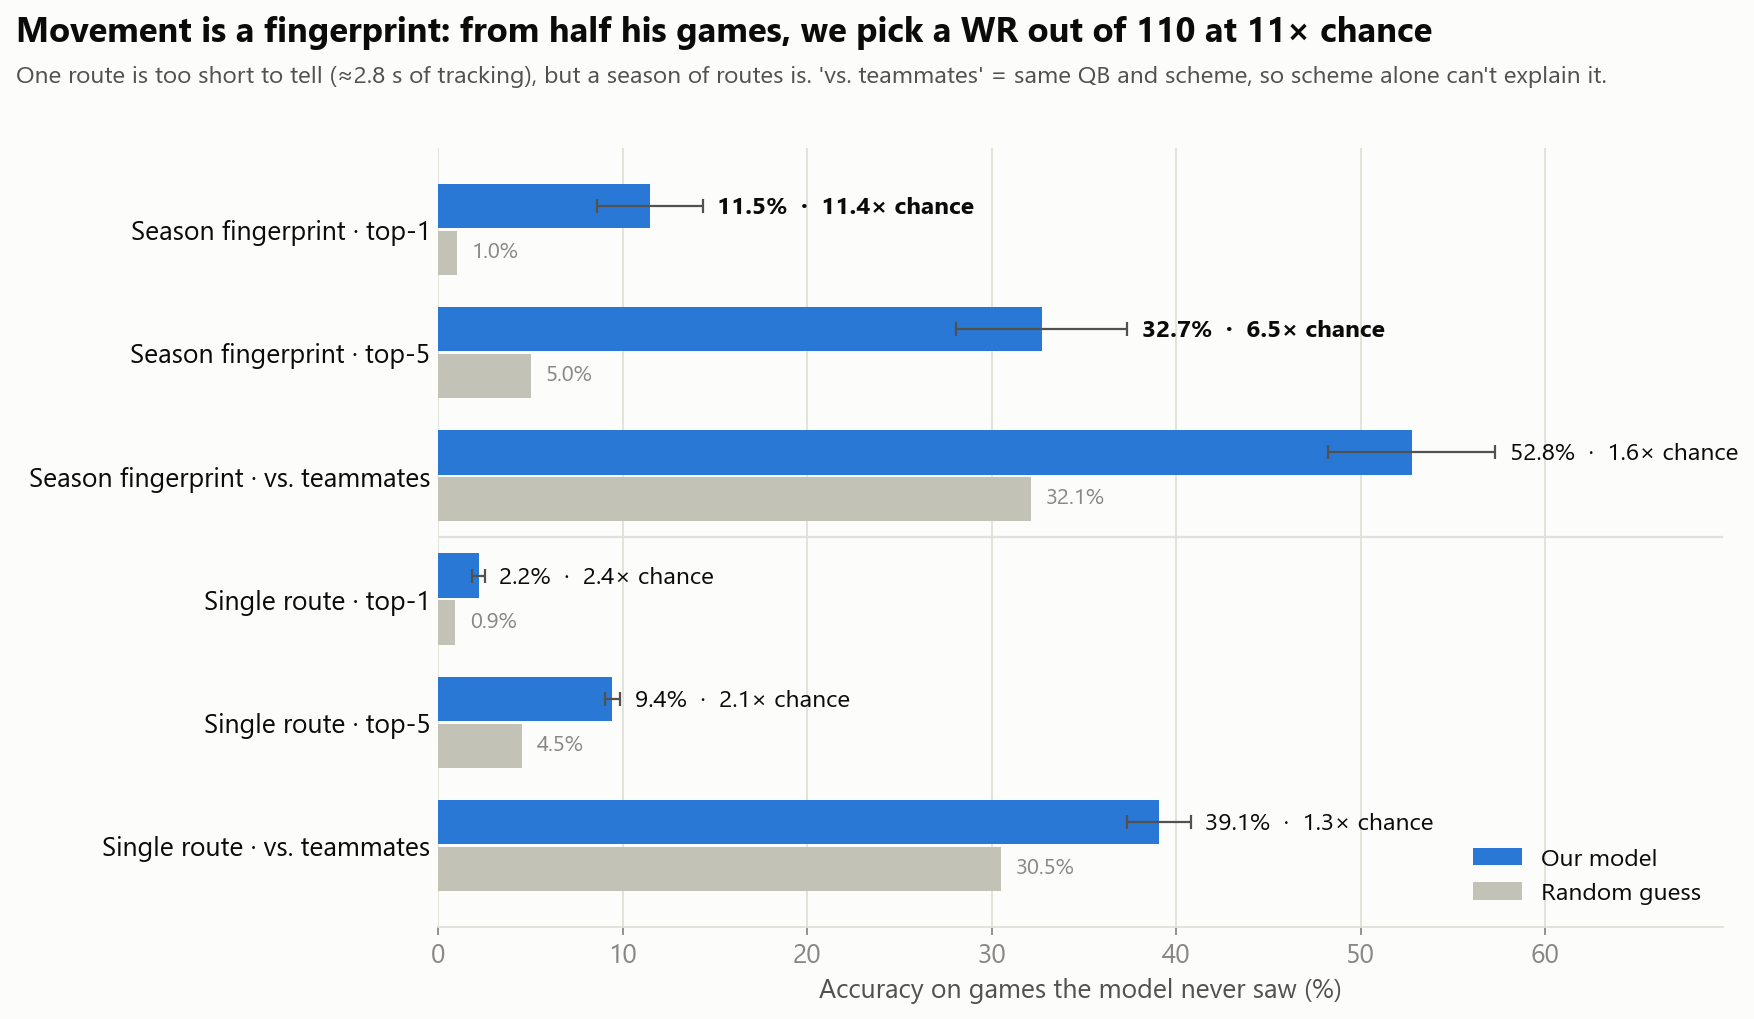

In [15]:
visuals.identification(d)
display(Image(OUT / "identification.png", width=900))

### Star vs. his budget doppelgänger

Each axis is a percentile among all 110 receivers (0 = lowest, 100 = highest).

Saved -> outputs\radar_cooper_kupp_vs_kj_osborn.png


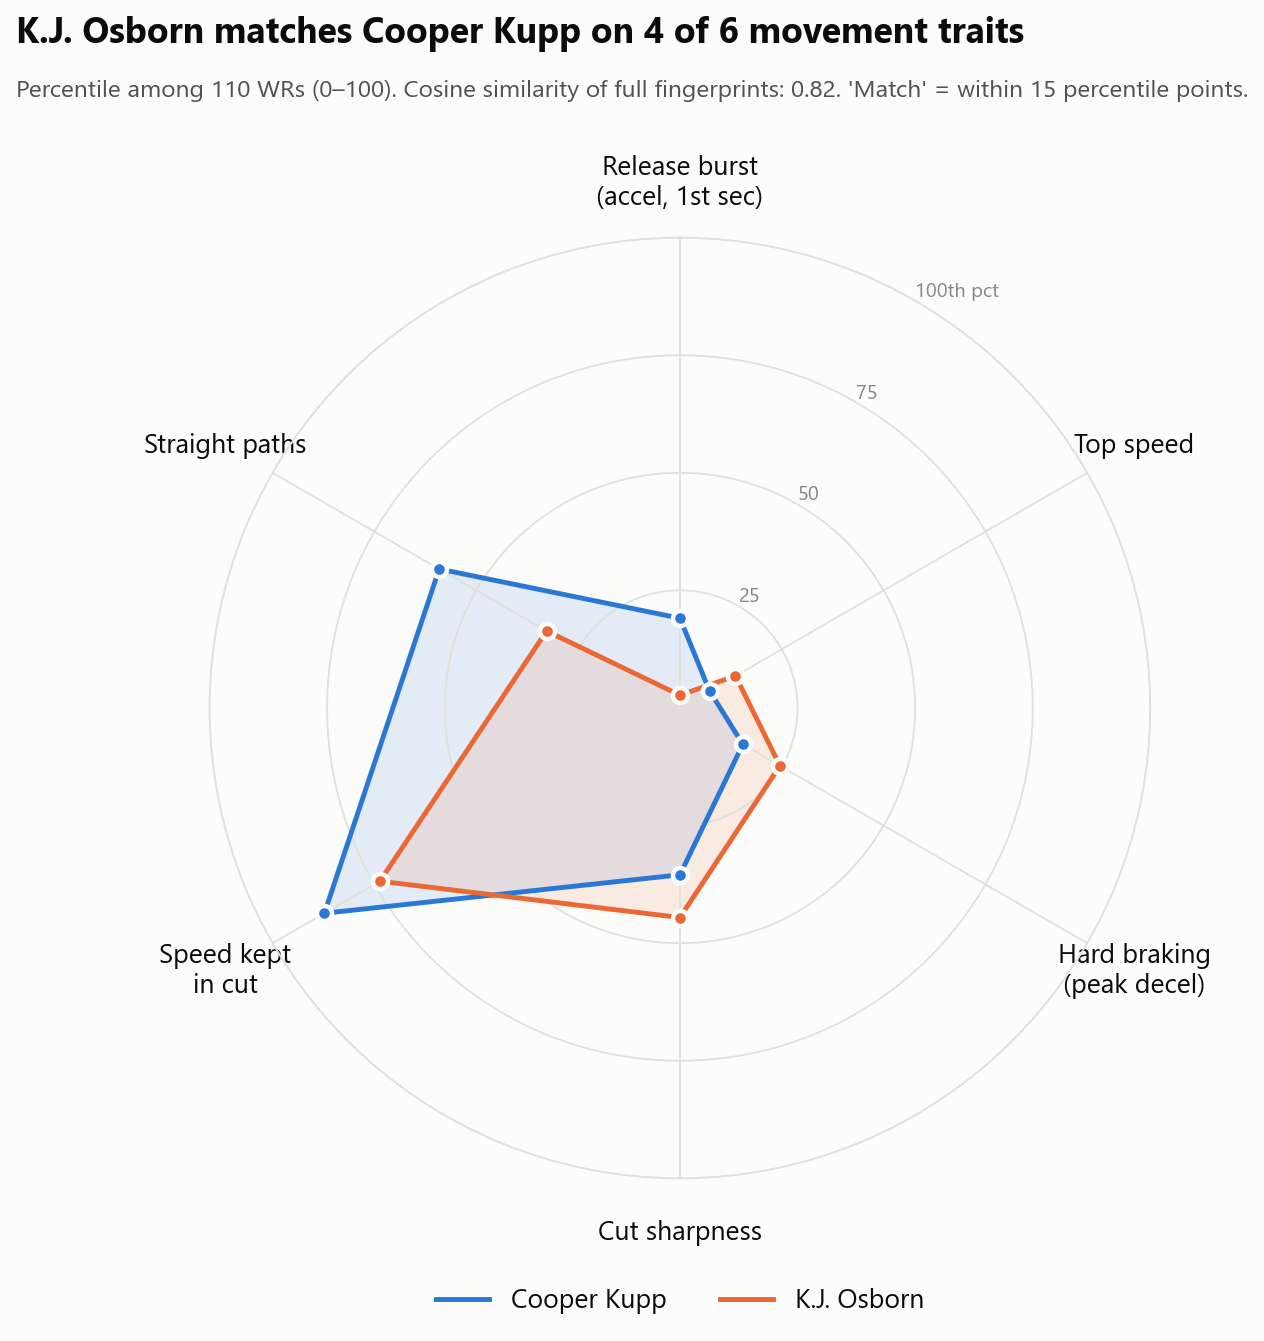

In [16]:
visuals.radar(d, STAR, DOUBLE)
display(Image(OUT / f"radar_{visuals.slug(STAR)}_vs_{visuals.slug(DOUBLE)}.png", width=650))

### Their routes, side by side

Ten random routes each, all moved to start at the same spot. The routes differ, but the **timing dots** (every 0.5 s)
are spaced alike, because the two players accelerate and run at the same speeds.

Saved -> outputs\route_overlay_cooper_kupp_vs_kj_osborn.png


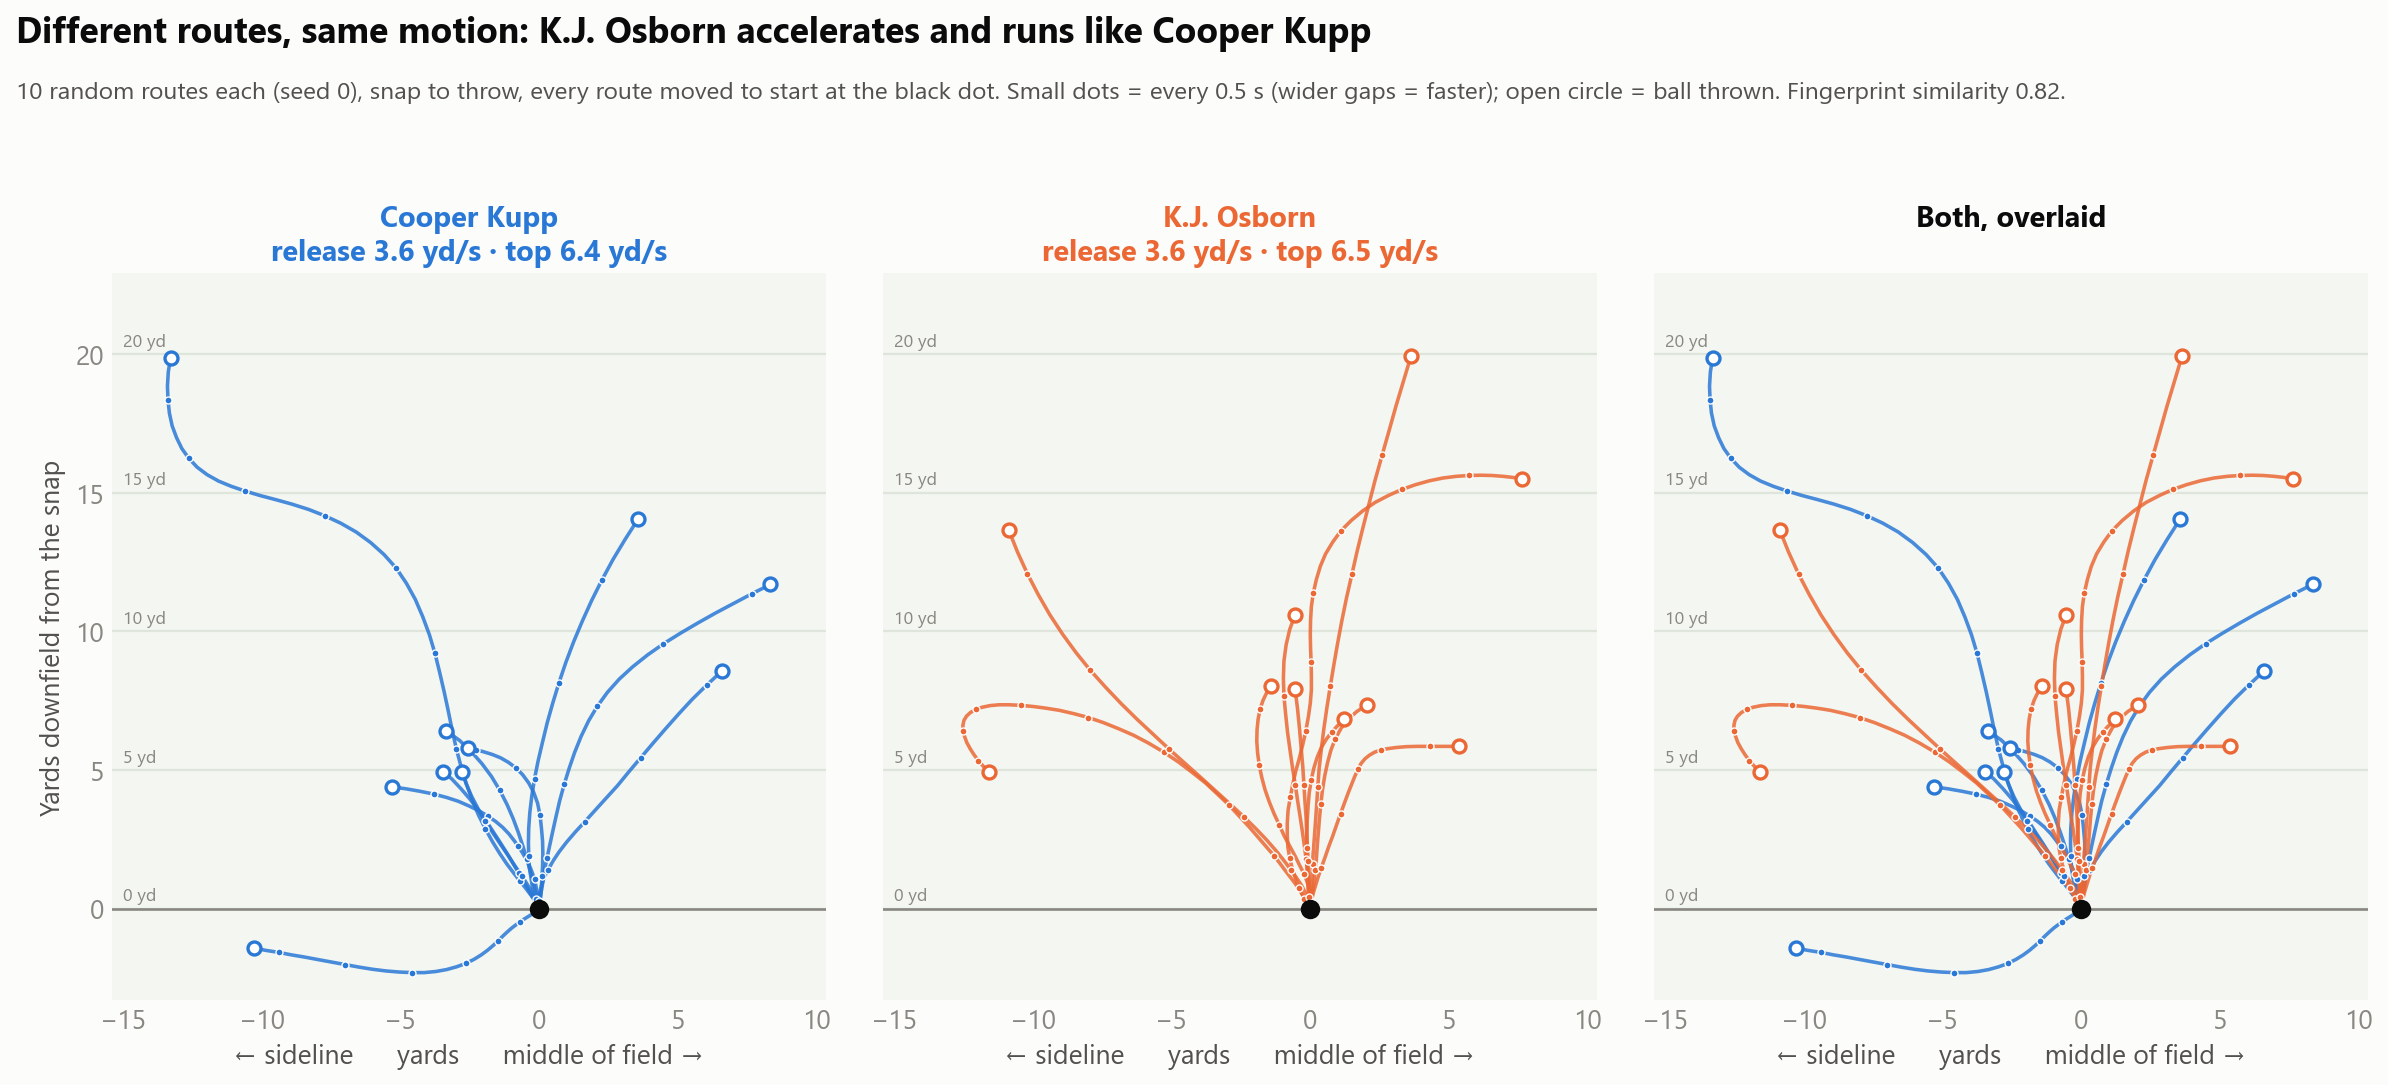

In [17]:
visuals.route_overlay(d, STAR, DOUBLE)
display(Image(OUT / f"route_overlay_{visuals.slug(STAR)}_vs_{visuals.slug(DOUBLE)}.png", width=1000))

### Top 10 budget doppelgängers

Saved -> outputs\budget_table.png  (top 10 total savings $153.3M)


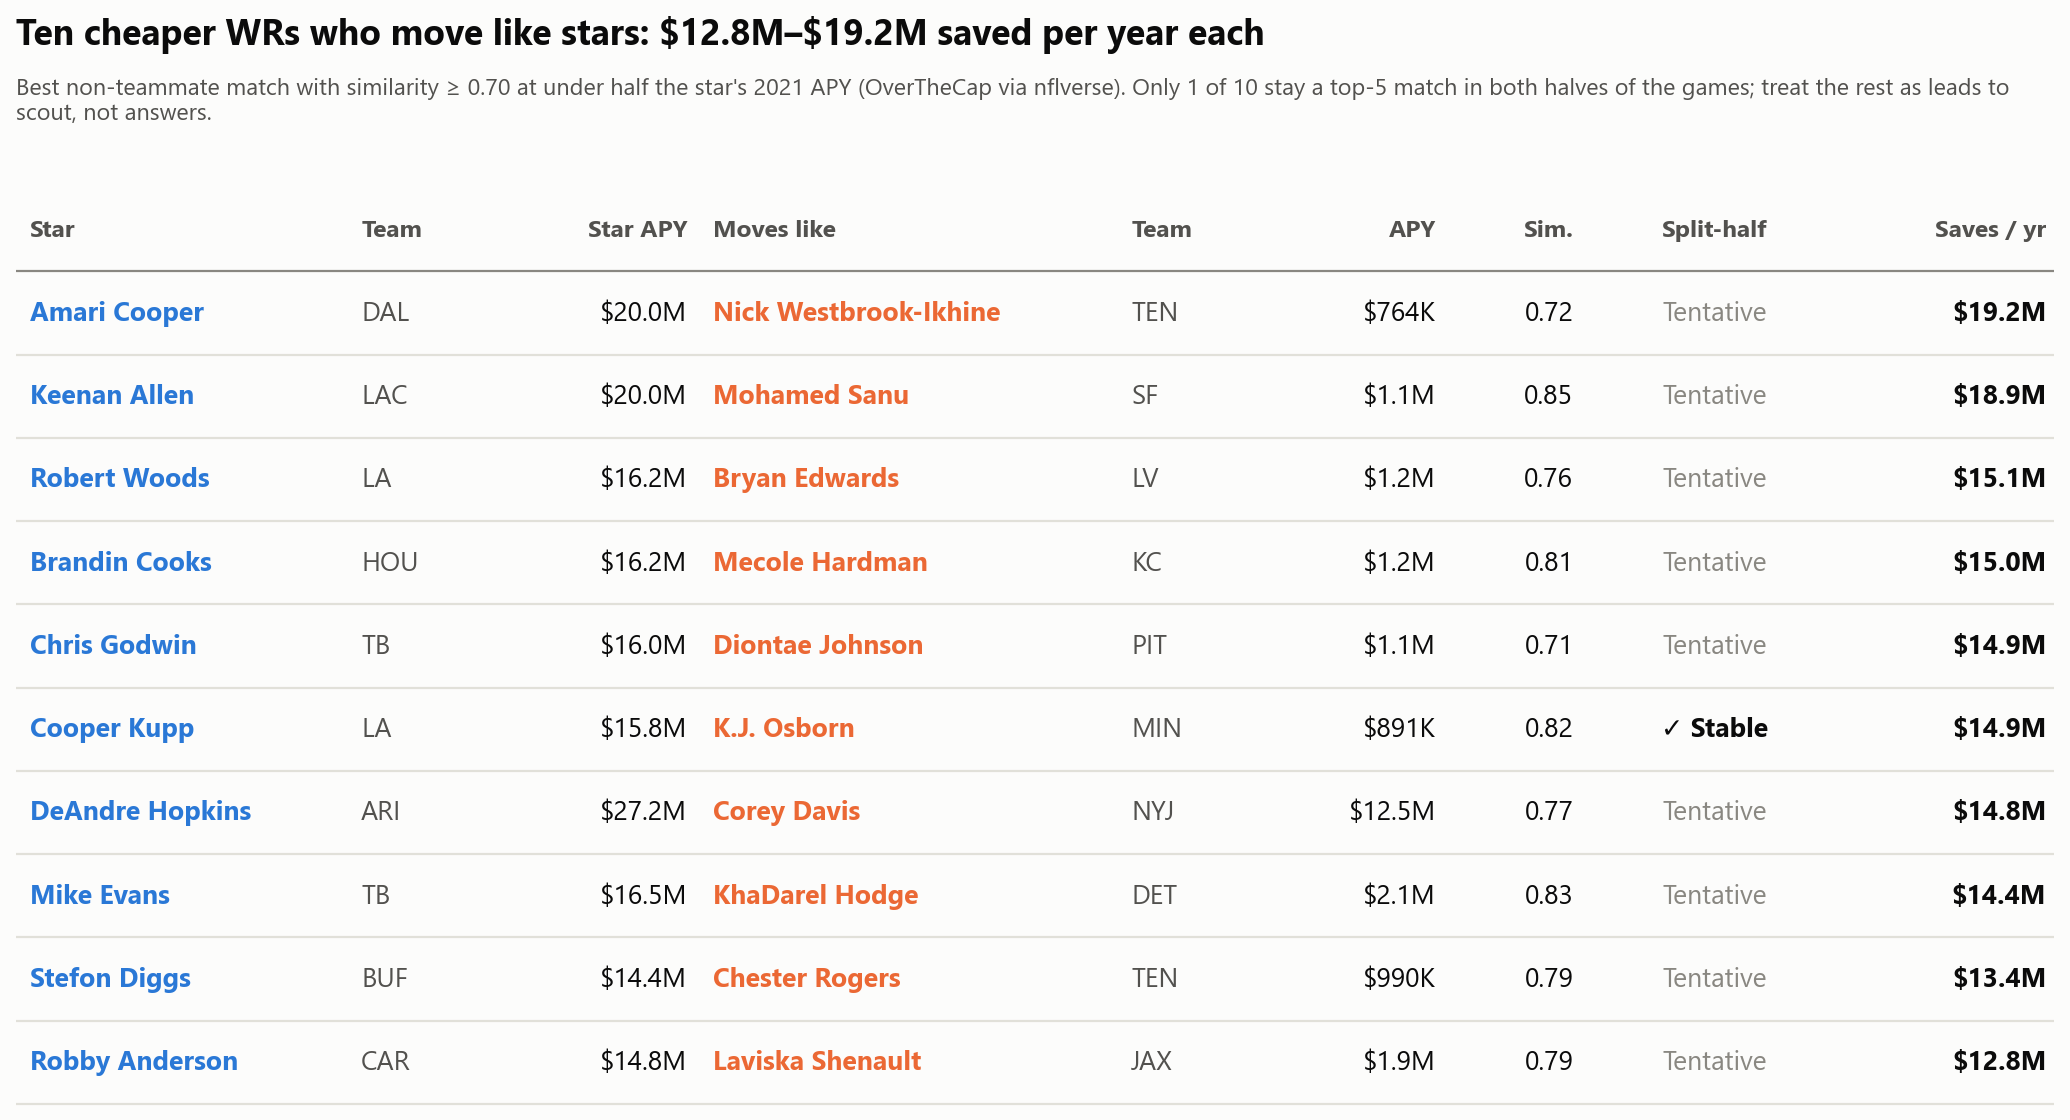

In [18]:
visuals.budget_table(d)
display(Image(OUT / "budget_table.png", width=1000))

## Takeaways

- **Movement style is real and measurable.** From half a season, we identify a receiver at about 11x chance, and he
  still beats chance among his own teammates.
- **It is mostly about speed.** Release burst and top speed carry most of the signal; cut features add little.
- **Similar movement does not cost the same.** Pay is unrelated to where a receiver sits on the map.
- **Be careful with single matches.** Only a few doppelgänger pairs hold up when we split the games in half.
  Cooper Kupp → K.J. Osborn is the strongest budget match: stable, similar build, about $14.9M a year cheaper.